# 02 — Unrolling vs Fixed-Point on Lorenz-63

This notebook compares the **unrolled** solver (standard backprop through
$K$ gradient steps, guided by a ConvLSTM gradient modulator) to the
**fixed-point** projection solver (repeated prior-projection with
observation re-insertion) on reconstructing partially-observed Lorenz-63
trajectories.

**Pipeline overview:**
1. Simulate L63 data with Diffrax
2. Extract patches, add masks and noise
3. Warm-start with `obs_interpolation_init` vs. zero initialisation
4. Run unrolled solver (`FourDVarNet1D`, K=10 steps)
5. Run fixed-point solver (`solve_4dvarnet_1d_fixedpoint`, K=10 steps)
6. Compare MSE across conditions with a bar chart

In [1]:
# (NNX removed in Epic 0 — vardax is now equinox-native)
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import vardax
from vardax import (
    Batch1D,
    BilinAEPrior1D,
    FourDVarNet1D,
    solve_4dvarnet_1d_fixedpoint,
)
from vardax._src.utils.dynamical_systems import simulate_lorenz63
from vardax._src.utils.patches import trajectory_to_xr_dataset, extract_patches
from vardax._src.utils.masks import regular_mask
from vardax._src.utils.noise import add_gaussian_noise
from vardax._src.utils.preprocessing import (
    xr_to_batch1d,
    obs_interpolation_init,
)
from vardax._src.utils.standardize import compute_scaler_params, apply_standardization
import xarray as xr

## 1. Simulate Lorenz-63 and build patches

In [2]:
key = jax.random.PRNGKey(0)
time_coords, states = simulate_lorenz63(
    key,
    sigma=10.0,
    rho=28.0,
    beta=8.0 / 3.0,
    dt=0.01,
    n_steps=5000,
    n_burn_in=1000,
)
print(f"states shape: {states.shape}")

ds = trajectory_to_xr_dataset(states, time_coords, feature_names=["X", "Y", "Z"])
# Split the trajectory in time *before* cutting windows, so no window
# straddles the boundary: windows drawn at random from one trajectory and
# split afterwards would leak test timesteps into the training set.
n_time = ds.sizes["time"]
ds_train = extract_patches(ds.isel(time=slice(0, int(0.8 * n_time))), n_patches=160, n_timesteps=20, seed=42)
ds_test = extract_patches(ds.isel(time=slice(int(0.8 * n_time), None)), n_patches=40, n_timesteps=20, seed=43)
ds_train = regular_mask(ds_train, variable="state", obs_interval=2)
ds_test = regular_mask(ds_test, variable="state", obs_interval=2)
ds_train = add_gaussian_noise(ds_train, variable="state", sigma=0.5, seed=0, name="obs")
ds_test = add_gaussian_noise(ds_test, variable="state", sigma=0.5, seed=1, name="obs")
mean, std = compute_scaler_params(ds_train, variable="state", mask_variable="mask")
ds_train = apply_standardization(ds_train, variables=["state", "obs"], mean=mean, std=std)
ds_test = apply_standardization(ds_test, variables=["state", "obs"], mean=mean, std=std)

batch_train = xr_to_batch1d(ds_train, state_var="state", obs_var="obs", mask_var="mask")
batch_test = xr_to_batch1d(ds_test, state_var="state", obs_var="obs", mask_var="mask")
print(f"train batch: {batch_train.input.shape}, test batch: {batch_test.input.shape}")

states shape: (5001, 3)
train batch: (160, 20, 3), test batch: (40, 20, 3)


## 2. Warm-start initialisation via `obs_interpolation_init`

Build a NaN-masked obs dataset so we can use `obs_interpolation_init`.

In [3]:
state_vals = ds_test["state"].values
mask_vals = ds_test["mask"].values.astype(bool)
obs_nan = np.where(mask_vals, ds_test["obs"].values, np.nan).astype(np.float32)
obs_nan_da = xr.DataArray(obs_nan, dims=ds_test["obs"].dims, coords=ds_test["obs"].coords)
ds_test_nan = ds_test.assign(obs_nan=obs_nan_da)

ds_test_init = obs_interpolation_init(
    ds_test_nan, variable="state", obs_variable="obs_nan"
)
x_init = jnp.array(ds_test_init["state_init"].values)
print(f"Warm-start init shape: {x_init.shape}")

# MSE of warm-start vs zero init
target = batch_test.target
mse_zero_init = float(jnp.mean((batch_test.input * batch_test.mask - target) ** 2))
mse_warm_init = float(jnp.mean((x_init - target) ** 2))
print(f"Zero-init MSE: {mse_zero_init:.4f}")
print(f"Warm-start MSE: {mse_warm_init:.4f}")

Warm-start init shape: (40, 20, 3)
Zero-init MSE: 0.6445
Warm-start MSE: 0.0654


## 3. Train FourDVarNet1D (unrolled solver)

In [4]:
B, T, N = batch_train.input.shape
model_unrolled = FourDVarNet1D(
    state_dim=N,
    n_time=T,
    latent_dim=8,
    hidden_dim=16,
    n_solver_steps=10,
    key=jax.random.PRNGKey(1),
)

model, train_losses, _ = vardax.examples.fit_demo(
    model_unrolled,
    [batch_train],
    n_epochs=5,
    lr=1e-3,
    verbose=True,
)
print(f"Final unrolled train loss: {train_losses[-1]:.4f}")

epoch 1/5 — train loss: 0.562356
epoch 2/5 — train loss: 0.524042
epoch 3/5 — train loss: 0.489939
epoch 4/5 — train loss: 0.459364
epoch 5/5 — train loss: 0.431853
Final unrolled train loss: 0.4319


## 4. Fixed-point solver (untrained prior)

In [5]:
prior = BilinAEPrior1D(state_dim=N, latent_dim=8, n_time=T, key=jax.random.PRNGKey(3))

out_fp = solve_4dvarnet_1d_fixedpoint(batch_test, prior, n_fp_steps=10)
print(f"Fixed-point output shape: {out_fp.shape}")

Fixed-point output shape: (40, 20, 3)


## 5. Evaluate unrolled solver on test batch

In [6]:
# `fit_demo` returns a new (trained) Equinox module; `model_unrolled` is the
# untrained initialisation.
out_unrolled = model(batch_test)
print(f"Unrolled output shape: {out_unrolled.shape}")

Unrolled output shape: (40, 20, 3)


## 6. Compare MSE across conditions

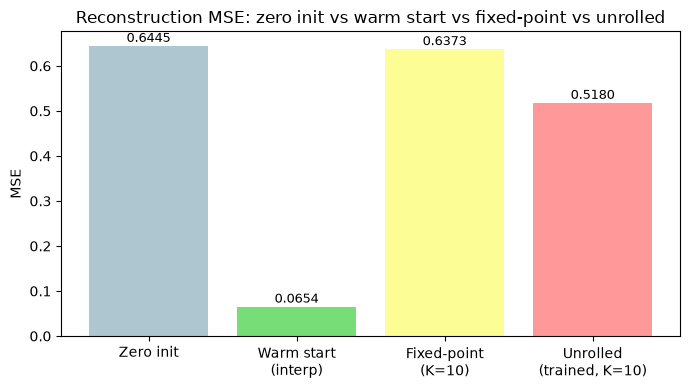

MSE summary:
  Zero init: 0.6445
  Warm start (interp): 0.0654
  Fixed-point (K=10): 0.6373
  Unrolled (trained, K=10): 0.5180


In [7]:
mse_fp = float(jnp.mean((out_fp - target) ** 2))
mse_unrolled = float(jnp.mean((out_unrolled - target) ** 2))

labels = ["Zero init", "Warm start\n(interp)", "Fixed-point\n(K=10)", "Unrolled\n(trained, K=10)"]
values = [mse_zero_init, mse_warm_init, mse_fp, mse_unrolled]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, values, color=["#aec6cf", "#77dd77", "#fdfd96", "#ff9999"])
ax.set_ylabel("MSE")
ax.set_title("Reconstruction MSE: zero init vs warm start vs fixed-point vs unrolled")
for bar, val in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        bar.get_height() + 0.002,
        f"{val:.4f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )
plt.tight_layout()
plt.show()
print("MSE summary:")
for label, val in zip(labels, values):
    print(f"  {label.replace(chr(10), ' ')}: {val:.4f}")